# ENZERA - 04 Synthetic theft attacks (Jokar et al., 2016)

**Question.** Jokar et al. (2016) describe typical ways a thief manipulates meter readings. If we inject these attacks
into the readings of customers labelled **normal**, does the deployed model notice?

**Setup.**
- Customers: **normal** customers from the **test split** (never used in training) with at least 365 observed days.
- Each customer gets each attack, starting on a random day between 2 years and 6 months before the end of the data and
  lasting until the end (the theft "starts" and continues). Missing days stay missing.
- Model: the deployed bundle `models/enzera_model.joblib`, unchanged.
- We compare each customer's risk score **before** and **after** the attack.

**Attacks** (daily-data versions of Jokar et al.'s attack types; α = random factor in [0.2, 0.8]):

| Attack | What the thief reports during the attack window |
|---|---|
| A1 constant reduction | real usage × α (one α per customer) |
| A2 zero period | 0 for a random 30-180-day period |
| A3 random daily reduction | real usage × a new α every day |
| A4 noisy average | customer's average × a new α every day |
| A5 flat average | customer's average, every day (hides the real profile) |
| A6 reversed order | the real readings in reverse order (same total) |

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from ml.features import compute_features, split_wide
from ml.scoring import load_bundle
from ml.train import SEED
import matplotlib.pyplot as plt
%matplotlib inline

bundle = load_bundle(ROOT / "models/enzera_model.joblib")
thr = bundle["threshold"]
ids, labels, dates, values = split_wide(pd.read_csv(ROOT / "data/raw/data.csv"))
idx = np.arange(len(ids))
tr, rest = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
te, demo = train_test_split(rest, test_size=0.50, stratify=labels[rest], random_state=SEED)

def risk(v):
    return bundle["model"].predict_proba(compute_features(v, dates).to_numpy())[:, 1]

# reference: score above which a customer is in the top 10% of the real test set
test_scores = risk(values[te])
top10_cut = np.sort(test_scores)[::-1][int(0.10 * len(te)) - 1]

normal = te[(labels[te] == 0) & ((~np.isnan(values[te])).sum(axis=1) >= 365)]
V0 = values[normal].copy()
print(f"{len(normal):,} normal test customers with >= 365 observed days; model {bundle['version']}, threshold {thr:.3f}, top-10% cut-off {top10_cut:.3f}")

4,471 normal test customers with >= 365 observed days; model xgb-20261114-1521, threshold 0.656, top-10% cut-off 0.620


In [2]:
rng = np.random.default_rng(SEED)
n, T = V0.shape
start = rng.integers(T - 730, T - 180, size=n)          # attack starts 2 years to 6 months before the end
window = np.arange(T)[None, :] >= start[:, None]      # True from the start day to the end
with np.errstate(all="ignore"):
    avg = np.nanmean(V0, axis=1, keepdims=True)

def attack(kind):
    V = V0.copy()
    if kind == "A1 constant reduction":
        V = np.where(window, V * rng.uniform(0.2, 0.8, size=(n, 1)), V)
    elif kind == "A2 zero period":
        length = rng.integers(30, 181, size=n)
        zero = window & (np.arange(T)[None, :] < (start + length)[:, None])
        V = np.where(zero & ~np.isnan(V), 0.0, V)
    elif kind == "A3 random daily reduction":
        V = np.where(window, V * rng.uniform(0.2, 0.8, size=V.shape), V)
    elif kind == "A4 noisy average":
        V = np.where(window & ~np.isnan(V), avg * rng.uniform(0.2, 0.8, size=V.shape), V)
    elif kind == "A5 flat average":
        V = np.where(window & ~np.isnan(V), avg, V)
    elif kind == "A6 reversed order":
        for i in range(n):
            s = start[i]; V[i, s:] = V[i, s:][::-1]
    return V.astype(np.float32)

before = risk(V0)
rows, after_scores = [], {}
for kind in ["A1 constant reduction", "A2 zero period", "A3 random daily reduction",
             "A4 noisy average", "A5 flat average", "A6 reversed order"]:
    a = risk(attack(kind)); after_scores[kind] = a
    rows.append({"attack": kind,
                 "flagged High after": (a >= thr).mean(),
                 "in top-10% zone after": (a >= top10_cut).mean(),
                 "median risk before": np.median(before), "median risk after": np.median(a),
                 "score went up": (a > before).mean()})
res = pd.DataFrame(rows).set_index("attack")
res.loc["(no attack: same customers)"] = [(before >= thr).mean(), (before >= top10_cut).mean(),
                                          np.median(before), np.median(before), np.nan]
res.to_csv(ROOT / "reports/attack_detection.csv")
res.round(3)

,flagged High after,in top-10% zone after,median risk before,median risk after,score went up
attack,,,,,
A1 constant reduction,0.029,0.036,0.174,0.181,0.424
A2 zero period,0.062,0.081,0.174,0.228,0.524
A3 random daily reduction,0.028,0.034,0.174,0.186,0.448
A4 noisy average,0.019,0.022,0.174,0.165,0.418
A5 flat average,0.022,0.029,0.174,0.082,0.179
A6 reversed order,0.060,0.074,0.174,0.181,0.489
(no attack: same customers),0.057,0.070,0.174,0.174,NaN


*Reading the table:* "flagged High" = risk score above the deployed threshold. "In top-10% zone" = score high enough to be among
the 10% riskiest real test customers (what an inspector with a 10% budget would visit). The last row is the false-alarm level
for the same honest customers before any attack.

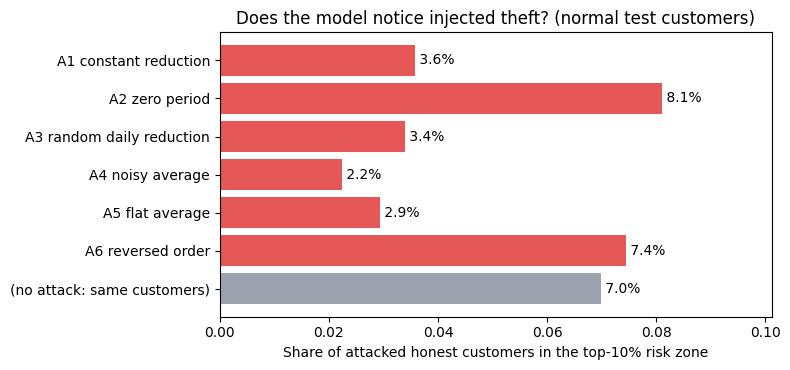

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = list(res.index)
vals = res["in top-10% zone after"].values
ax.barh(order[::-1], vals[::-1], color=["#9CA3AF"] + ["#E45756"] * (len(order) - 1))
for i, v in enumerate(vals[::-1]):
    ax.text(v, i, f" {v:.1%}", va="center")
ax.set_xlim(0, max(vals) * 1.25); ax.set_xlabel("Share of attacked honest customers in the top-10% risk zone")
ax.set_title("Does the model notice injected theft? (normal test customers)")
fig.tight_layout(); fig.savefig(ROOT / "reports/attack_detection.png", dpi=120); plt.show()

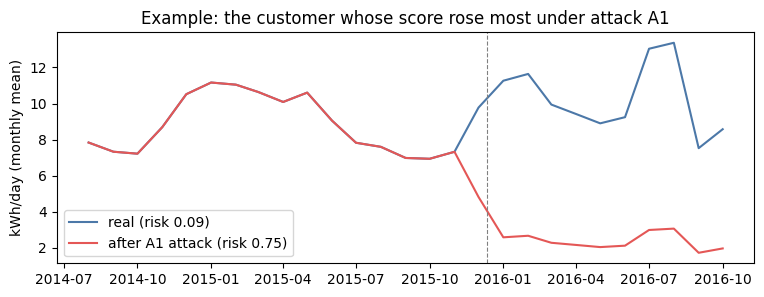

In [4]:
i = int(np.argmax(after_scores["A1 constant reduction"] - before))
fig, ax = plt.subplots(figsize=(9, 3))
s0 = pd.Series(V0[i], index=dates).resample("MS").mean()
s1 = pd.Series(attack("A1 constant reduction")[i], index=dates).resample("MS").mean()
ax.plot(s0.index, s0.values, label=f"real (risk {before[i]:.2f})", color="#4C78A8")
ax.plot(s1.index, s1.values, label=f"after A1 attack (risk {after_scores['A1 constant reduction'][i]:.2f})", color="#E45756")
ax.axvline(dates[start[i]], color="grey", ls="--", lw=0.8); ax.legend(); ax.set_ylabel("kWh/day (monthly mean)")
ax.set_title("Example: the customer whose score rose most under attack A1")
plt.show()

*(Note: attack A1 is re-drawn with new random factors for this plot, so the second curve is one example draw.)*

## Conclusion

**The deployed model does not detect synthetic theft attacks.** This is an important limitation, not a bug.

- Before any attack, 5.7% of these 4,471 honest customers are flagged High and 7.0% fall in the top-10% risk zone (false alarms).
- After the attacks, the share in the top-10% zone is **3.6% (A1), 8.1% (A2), 3.4% (A3), 2.2% (A4), 2.9% (A5) and 7.4% (A6)**.
  Only the zero-period attack (A2) raises scores at all (median risk 0.174 → 0.228), and only slightly. Reducing or
  flattening consumption (A1, A3-A5) makes customers look *safer*: the flat-average attack A5 halves the median risk
  (0.174 → 0.082) and raises the score of only 17.9% of customers.
- Reversing the order of readings (A6) changes almost nothing. With daily data and no time-of-use prices, it is also the
  least harmful attack.

**Why.** The model learns from SGCC's labels, i.e. from customers who were *caught*. As the EDA showed, caught customers in
SGCC are on average **larger, more variable consumers with rising usage**. The model therefore associates theft with high,
erratic consumption, and a synthetic attack that lowers or smooths consumption moves a customer *away* from that profile.

**What this means.**
1. ENZERA is good at finding customers who resemble past confirmed thieves (PR-AUC 0.376 on real labels). It is **not** a
   general detector of the textbook attack patterns.
2. A production system should combine it with rule-based or self-comparison checks, e.g. a sudden sustained drop compared
   with the customer's own history or with similar neighbours, and keep retraining on new inspection outcomes (feature #11),
   so that new theft styles enter the labels.
3. Synthetic attacks could also be added to the *training* data (as Jokar et al. do) to teach the model these patterns. That
   is future work.